Tugas Machine Learning 10

10.1 Persiapan LIbrary

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, \
    DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

10.2 Import Dataset

In [ ]:
rng = np.random.default_rng(42)
n = 300
X = np.vstack([rng.normal([5, 200000], [1.5, 30000], (100, 2)),
    rng.normal([15, 800000], [2, 50000], (100, 2)),
    rng.normal([2, 50000], [0.8, 15000], (100, 2)), ])

10.3 Preprocessing

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scaling WAJIB karena
    # K-Means berbasis jarak

10.4 Training Model

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3,
    linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

10.5 Evaluasi

In [ ]:
print("Silhouette Score K-Means      :",
    round(silhouette_score(X_scaled, labels_kmeans), 3))
print("Silhouette Score Agglomerative:",
    round(silhouette_score(X_scaled, labels_agglo), 3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)   :", n_noise)

Silhouette Score K-Means      : 0.711
Silhouette Score Agglomerative: 0.709
Jumlah noise point (DBSCAN)   : 0


10.6 Visualisasi

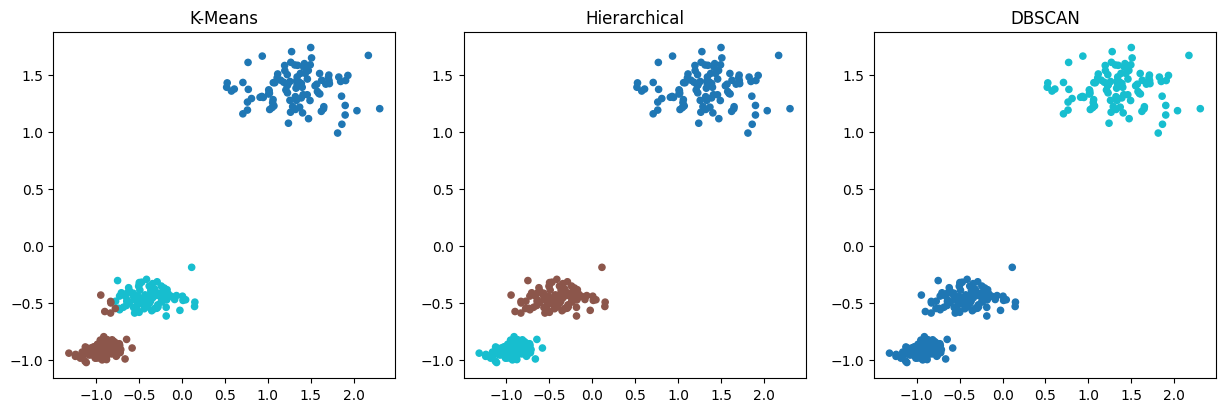

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes, [labels_kmeans,
    labels_agglo, labels_dbscan], ["K-Means", "Hierarchical",
    "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels,
        cmap="tab10", s=20)
    ax.set_title(judul)
plt.show()

10.7 Praktikum 1

k=2  inertia=   47.72  silhouette=0.831
k=3  inertia=   23.09  silhouette=0.711
k=4  inertia=   15.16  silhouette=0.577
k=5  inertia=   11.98  silhouette=0.524
k=6  inertia=    8.97  silhouette=0.525
k=7  inertia=    7.78  silhouette=0.447
k=8  inertia=    6.97  silhouette=0.425
k=9  inertia=    6.19  silhouette=0.387
k=10 inertia=    5.51  silhouette=0.380

Silhouette tertinggi : k = 2 (0.831)
Titik siku (Elbow)   : k = 3 (silhouette = 0.711)
k optimal yang dipilih: k = 3


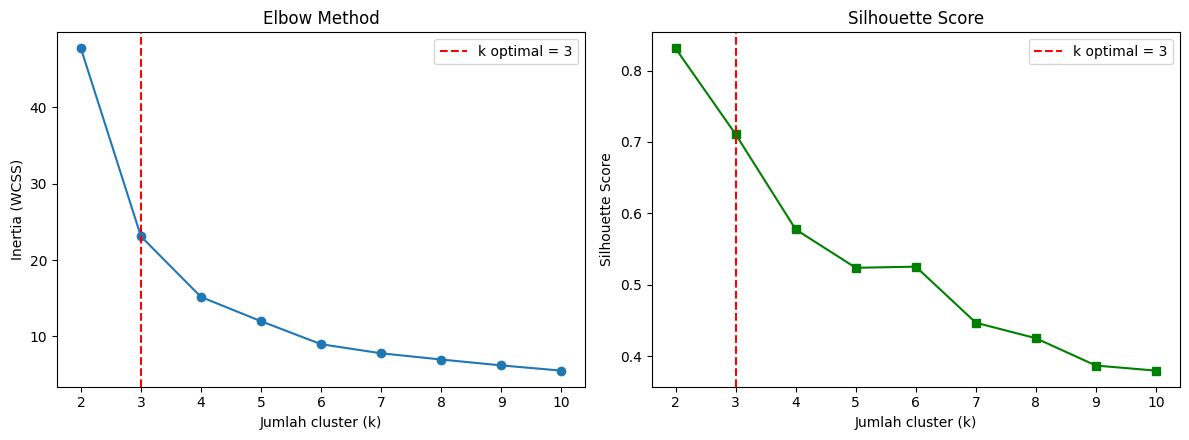

In [ ]:
k_range = range(2, 11)
inertia_list, sil_list = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, lab))
    print(f"k={k:<2} inertia={km.inertia_:8.2f}  silhouette={sil_list[-1]:.3f}")

ks = list(k_range)
k_silhouette = ks[int(np.argmax(sil_list))]

turunan2 = [inertia_list[i - 1] - 2 * inertia_list[i] + inertia_list[i + 1]
            for i in range(1, len(ks) - 1)]
k_elbow = ks[1 + int(np.argmax(turunan2))]
print(f"\nSilhouette tertinggi : k = {k_silhouette} "
      f"({max(sil_list):.3f})")
print(f"Titik siku (Elbow)   : k = {k_elbow} "
      f"(silhouette = {sil_list[ks.index(k_elbow)]:.3f})")

k_optimal = k_elbow
print(f"k optimal yang dipilih: k = {k_optimal}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(list(k_range), inertia_list, "o-")
ax1.axvline(k_optimal, color="red", linestyle="--",
            label=f"k optimal = {k_optimal}")
ax1.set_xlabel("Jumlah cluster (k)")
ax1.set_ylabel("Inertia (WCSS)")
ax1.set_title("Elbow Method")
ax1.legend()

ax2.plot(list(k_range), sil_list, "s-", color="green")
ax2.axvline(k_optimal, color="red", linestyle="--",
            label=f"k optimal = {k_optimal}")
ax2.set_xlabel("Jumlah cluster (k)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Silhouette Score")
ax2.legend()
plt.tight_layout()
plt.savefig("elbow_silhouette.png", dpi=110)
plt.show()

10.7 Praktikum 2


=== Praktikum 10.7: Perbandingan Tiga Algoritma ===

Sensitivitas eps DBSCAN (min_samples=5):
eps    Cluster  Noise  Silhouette
0.05         9    124       0.561
0.1          4     37       0.601
0.15         4     10       0.594
0.2          3      4       0.712
0.3          2      0       0.831

Algoritma                          Cluster  Noise  Silhouette
K-Means (k=3)                            3      0       0.711   ukuran: {0: 100, 1: 106, 2: 94}
Hierarchical (k=3)                       3      0       0.709   ukuran: {0: 100, 1: 100, 2: 100}
DBSCAN (eps=0.2, min_samples=5)          3      4       0.712   ukuran: {-1: 4, 0: 99, 1: 97, 2: 100}


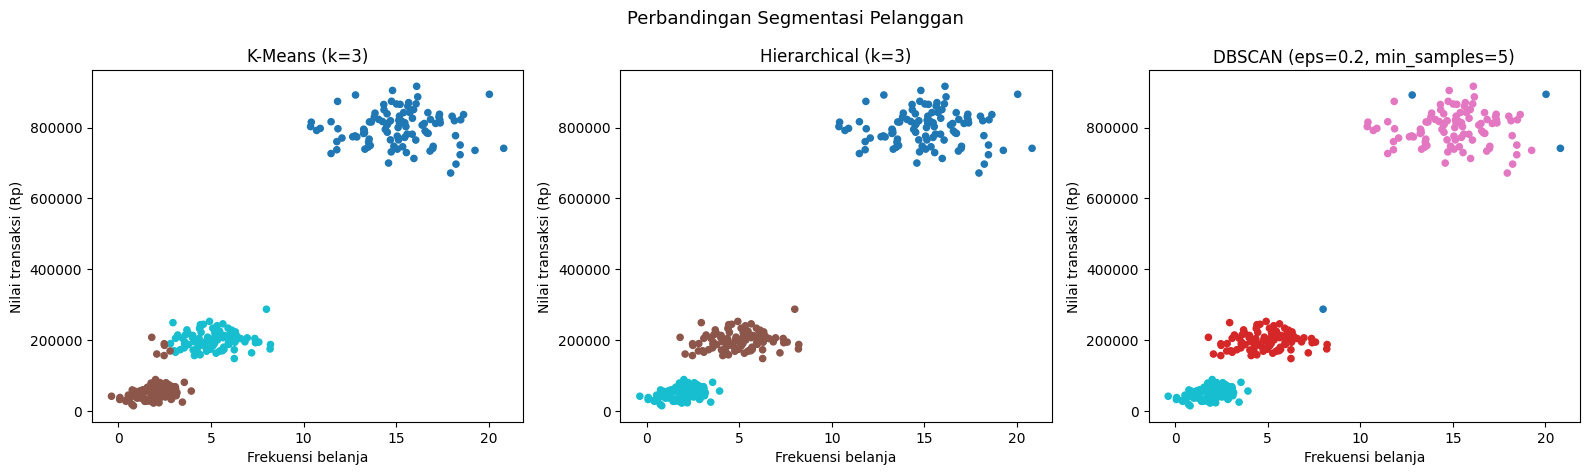

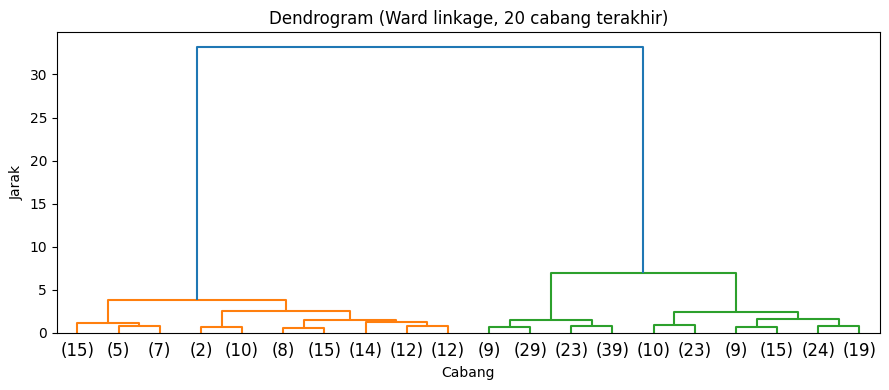

In [ ]:
print("\n=== Praktikum 10.7: Perbandingan Tiga Algoritma ===")
km = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
hasil = {
    f"K-Means (k={k_optimal})": km.fit_predict(X_scaled),
    f"Hierarchical (k={k_optimal})": AgglomerativeClustering(
        n_clusters=k_optimal, linkage="ward").fit_predict(X_scaled),
    "DBSCAN (eps=0.2, min_samples=5)": DBSCAN(
        eps=0.2, min_samples=5).fit_predict(X_scaled),
}

print("\nSensitivitas eps DBSCAN (min_samples=5):")
print(f"{'eps':<6}{'Cluster':>8}{'Noise':>7}{'Silhouette':>12}")
for eps in [0.05, 0.1, 0.15, 0.2, 0.3]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    mask = lab != -1
    nc = len(set(lab[mask]))
    sil = (f"{silhouette_score(X_scaled[mask], lab[mask]):.3f}"
           if nc >= 2 else "n/a")
    print(f"{eps:<6}{nc:>8}{int((~mask).sum()):>7}{sil:>12}")
print()

print(f"{'Algoritma':<34}{'Cluster':>8}{'Noise':>7}{'Silhouette':>12}")
for nama, lab in hasil.items():
    mask = lab != -1
    n_cluster = len(set(lab[mask]))
    n_noise = int((~mask).sum())
    if n_cluster >= 2:
        sil = f"{silhouette_score(X_scaled[mask], lab[mask]):.3f}"
    else:
        sil = "n/a"
    ukuran = {int(c): int((lab == c).sum()) for c in sorted(set(lab))}
    print(f"{nama:<34}{n_cluster:>8}{n_noise:>7}{sil:>12}   ukuran: {ukuran}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nama, lab) in zip(axes, hasil.items()):
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", s=20)
    ax.set_xlabel("Frekuensi belanja")
    ax.set_ylabel("Nilai transaksi (Rp)")
    ax.set_title(nama)
plt.suptitle("Perbandingan Segmentasi Pelanggan", fontsize=13)
plt.tight_layout()
plt.savefig("perbandingan_clustering.png", dpi=110)
plt.show()

Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(9, 4))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Dendrogram (Ward linkage, 20 cabang terakhir)")
plt.xlabel("Cabang")
plt.ylabel("Jarak")
plt.tight_layout()
plt.savefig("dendrogram.png", dpi=110)
plt.show()

10.7 Praktikum

Algoritma                          Cluster  Noise  Silhouette
K-Means (k=3)                            3      0       0.711   {0: 100, 1: 106, 2: 94}
Hierarchical (k=3)                       3      0       0.709   {0: 100, 1: 100, 2: 100}
DBSCAN (eps=0.2, min_samples=5)          3      4       0.712   {-1: 4, 0: 99, 1: 97, 2: 100}


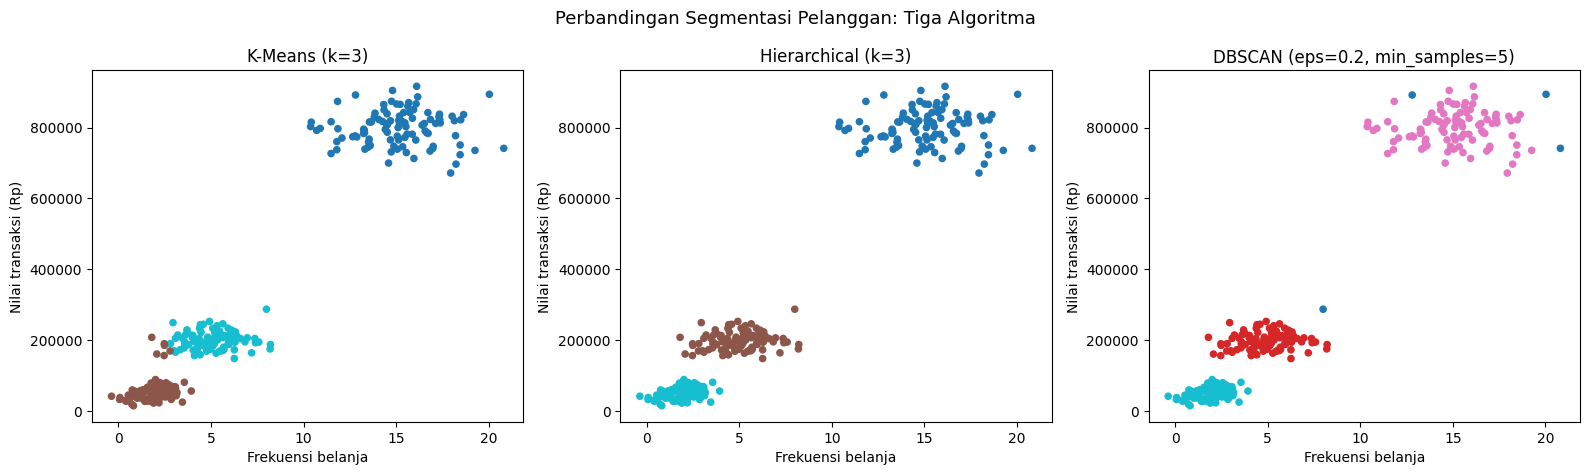


ANALISIS
1. Ketiga algoritma menemukan 3 segmen dengan Silhouette Score hampir sama
   (sekitar 0.71), sehingga dari sisi metrik tidak ada pemenang mutlak.
2. Hierarchical (Ward) paling masuk akal secara bisnis: ukuran segmen paling
   seimbang (100/100/100) dan dendrogram membantu menjelaskan hubungan antar
   segmen kepada pihak non-teknis.
3. K-Means hasilnya hampir sama dan paling cepat untuk data besar, namun batas
   segmen bawah sedikit bergeser (106 vs 94 pelanggan).
4. DBSCAN unggul dalam mengidentifikasi pelanggan berpola tidak biasa (4 noise
   point) yang perlu ditelaah terpisah, tetapi sangat sensitif terhadap eps:
   eps=0.3 hanya menghasilkan 2 cluster karena dua segmen bawah menyatu.
5. Segmen yang terbentuk: (a) frekuensi rendah & nilai transaksi rendah
   -> pelanggan hemat/baru, (b) frekuensi sedang & nilai sedang -> pelanggan
   reguler, (c) frekuensi tinggi & nilai transaksi tinggi -> pelanggan bernilai
   tinggi (prioritas program loyalitas).



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)
X = np.vstack([rng.normal([5, 200000], [1.5, 30000], (100, 2)),
               rng.normal([15, 800000], [2, 50000], (100, 2)),
               rng.normal([2, 50000], [0.8, 15000], (100, 2))])
X_scaled = StandardScaler().fit_transform(X)

hasil = {
    "K-Means (k=3)": KMeans(n_clusters=3, n_init=10,
                            random_state=42).fit_predict(X_scaled),
    "Hierarchical (k=3)": AgglomerativeClustering(
        n_clusters=3, linkage="ward").fit_predict(X_scaled),
    "DBSCAN (eps=0.2, min_samples=5)": DBSCAN(
        eps=0.2, min_samples=5).fit_predict(X_scaled),
}

print(f"{'Algoritma':<34}{'Cluster':>8}{'Noise':>7}{'Silhouette':>12}")
for nama, lab in hasil.items():
    mask = lab != -1                      # noise (-1) tidak ikut dihitung
    n_cluster = len(set(lab[mask]))
    n_noise = int((~mask).sum())
    sil = silhouette_score(X_scaled[mask], lab[mask])
    ukuran = {int(c): int((lab == c).sum()) for c in sorted(set(lab))}
    print(f"{nama:<34}{n_cluster:>8}{n_noise:>7}{sil:>12.3f}   {ukuran}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nama, lab) in zip(axes, hasil.items()):
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", s=20)
    ax.set_xlabel("Frekuensi belanja")
    ax.set_ylabel("Nilai transaksi (Rp)")
    ax.set_title(nama)
plt.suptitle("Perbandingan Segmentasi Pelanggan: Tiga Algoritma", fontsize=13)
plt.tight_layout()
plt.savefig("praktikum_10_7.png", dpi=110)
plt.show()
print("""
ANALISIS
1. Ketiga algoritma menemukan 3 segmen dengan Silhouette Score hampir sama
   (sekitar 0.71), sehingga dari sisi metrik tidak ada pemenang mutlak.
2. Hierarchical (Ward) paling masuk akal secara bisnis: ukuran segmen paling
   seimbang (100/100/100) dan dendrogram membantu menjelaskan hubungan antar
   segmen kepada pihak non-teknis.
3. K-Means hasilnya hampir sama dan paling cepat untuk data besar, namun batas
   segmen bawah sedikit bergeser (106 vs 94 pelanggan).
4. DBSCAN unggul dalam mengidentifikasi pelanggan berpola tidak biasa (4 noise
   point) yang perlu ditelaah terpisah, tetapi sangat sensitif terhadap eps:
   eps=0.3 hanya menghasilkan 2 cluster karena dua segmen bawah menyatu.
5. Segmen yang terbentuk: (a) frekuensi rendah & nilai transaksi rendah
   -> pelanggan hemat/baru, (b) frekuensi sedang & nilai sedang -> pelanggan
   reguler, (c) frekuensi tinggi & nilai transaksi tinggi -> pelanggan bernilai
   tinggi (prioritas program loyalitas).
""")